<a href="https://colab.research.google.com/github/aashwill/tokens-to-megawatts/blob/main/day2_dates_and_weekly_rollups.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 2: Dates and weekly roll-ups

**Tokens to Megawatts, Layer 0, Day 2** · about 50 minutes (plus the Kaggle lessons below)

Capacity data is time data. Today you learn to turn hourly readings into the daily and weekly numbers a capacity review is built on, and the traps that come with dates. Same rules as Day 1: one cell at a time, **predict before you run**, try the ✏️ exercises before peeking at the solutions at the bottom.

**Before this notebook (about 35 min):** Kaggle Learn *Pandas*, lessons 1–3 (Creating, Reading and Writing · Indexing, Selecting and Assigning · Summary Functions and Maps). For each new command, jot the SQL equivalent in a comment.

| Part | Topic | Time |
|---|---|---|
| 1 | Write and read a CSV, and the date-parsing trap | 5 min |
| 2 | Date parts: day, hour, weekday, date-range filters | 8 min |
| 3 | Daily roll-up: peak vs average | 8 min |
| 4 | Weekly roll-up and the partial-week trap | 8 min |
| 5 | Window functions: rolling average, week-over-week growth | 7 min |
| 6 | Pivot by GPU type, and why the sum of peaks isn't the peak | 6 min |
| 7 | Trace-style time and GPU-hours | 5 min |
| 8 | Chart, four questions, wrap-up | 5 min |

---
## Setup: hourly GPU telemetry (synthetic)
8 weeks of **hourly** readings of GPUs in use, for two GPU types. It has a daily cycle, a weekend dip, growth and noise, like real fleet telemetry. Read the comments, then run it.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=7)

hours = pd.date_range("2026-03-04", periods=56 * 24, freq="h")   # 56 days of hourly timestamps

rows = []
for gpu_type, base, daily_growth in [("H100", 700, 0.003), ("B200", 250, 0.008)]:
    for ts in hours:
        day_index = (ts - hours[0]).days
        growth = 1 + daily_growth * day_index                        # demand trends up
        daily_cycle = 1 + 0.10 * np.sin((ts.hour - 9) / 24 * 2 * np.pi)  # busier mid-day
        weekend = 0.88 if ts.dayofweek >= 5 else 1.0                 # Sat/Sun dip
        noise = rng.normal(1, 0.03)
        rows.append({
            "timestamp": ts,
            "gpu_type": gpu_type,
            "gpus_in_use": round(base * growth * daily_cycle * weekend * noise),
        })

pd.DataFrame(rows).to_csv("gpu_telemetry_hourly.csv", index=False)   # save it like a real export
print("saved", len(rows), "rows")

saved 2688 rows


---
## Part 1: Read a CSV, and the date-parsing trap

| SQL / DuckDB | pandas |
|---|---|
| `SELECT * FROM read_csv('file.csv')` | `pd.read_csv("file.csv")` |

In [8]:
raw = pd.read_csv("gpu_telemetry_hourly.csv")
print(raw.dtypes)
raw.head()

timestamp      object
gpu_type       object
gpus_in_use     int64
dtype: object


,timestamp,gpu_type,gpus_in_use
0,2026-03-04 00:00:00,H100,651
1,2026-03-04 01:00:00,H100,645
2,2026-03-04 02:00:00,H100,627
3,2026-03-04 03:00:00,H100,613
4,2026-03-04 04:00:00,H100,624


Look at the type of `timestamp`: it's `object` (or `str`), i.e. **text**, not a date. Text dates sort and compare as strings, and none of today's date tools work on them. Fix it when you load:

In [10]:
telemetry = pd.read_csv("gpu_telemetry_hourly.csv", parse_dates=["timestamp"])
print(telemetry.dtypes)
print(telemetry["timestamp"].min(), "→", telemetry["timestamp"].max())

timestamp      datetime64[ns]
gpu_type               object
gpus_in_use             int64
dtype: object
2026-03-04 00:00:00 → 2026-04-28 23:00:00


If a column is already loaded as text, `pd.to_datetime(df["col"])` converts it. **Habit:** after every `read_csv`, check `dtypes`.

---
## Part 2: Date parts and date filters

`.dt` unlocks date parts, like `EXTRACT(...)` or `date_part(...)` in SQL.

In [11]:
telemetry["day"] = telemetry["timestamp"].dt.floor("D")          # date_trunc('day', timestamp)
telemetry["hour"] = telemetry["timestamp"].dt.hour               # EXTRACT(hour FROM timestamp)
telemetry["weekday"] = telemetry["timestamp"].dt.day_name()      # dayname(timestamp)

telemetry.head(3)

,timestamp,gpu_type,gpus_in_use,day,hour,weekday
0,2026-03-04 00:00:00,H100,651,2026-03-04,0,Wednesday
1,2026-03-04 01:00:00,H100,645,2026-03-04,1,Wednesday
2,2026-03-04 02:00:00,H100,627,2026-03-04,2,Wednesday


`floor("D")` keeps a real date-time (midnight), so it still sorts and plots correctly. Avoid `.dt.date` for roll-ups; it turns values into plain Python dates that pandas handles less well.

Filtering by date works with strings once the column is a real date:

In [12]:
# WHERE timestamp >= '2026-03-09' AND timestamp < '2026-03-16'
one_week = telemetry[(telemetry["timestamp"] >= "2026-03-09") & (telemetry["timestamp"] < "2026-03-16")]
print(one_week["timestamp"].min(), "→", one_week["timestamp"].max(), "|", len(one_week), "rows")

2026-03-09 00:00:00 → 2026-03-15 23:00:00 | 336 rows


Use `>=` start and `<` the day *after* the end. `<= "2026-03-15"` would mean "up to midnight on the 15th" and silently drop that day's other 23 hours.

✏️ **Exercise 1.** Average `gpus_in_use` by `weekday` across the whole period (all GPU types together). Which day is quietest? Does that match how the data was built?

In [13]:
# ✏️ Exercise 1: your code here
telemetry.groupby('weekday').gpus_in_use.mean()

,gpus_in_use
weekday,
Friday,529.223958
Monday,535.348958
Saturday,468.153646
Sunday,468.875000
Thursday,527.015625
Tuesday,536.427083
Wednesday,523.127604


---
## Part 3: Daily roll-up: peak vs average

First, the total fleet per hour (both GPU types added), then roll hours up to days. **Named aggregation** gives each result column a name, like `AS` in SQL:

```sql
SELECT date_trunc('day', timestamp) AS day,
       AVG(gpus_in_use) AS avg_gpus,
       MAX(gpus_in_use) AS peak_gpus
FROM fleet GROUP BY 1
```

In [27]:
fleet = telemetry.groupby("timestamp", as_index=False)["gpus_in_use"].sum()   # all GPU types per hour
fleet["day"] = fleet["timestamp"].dt.floor("D")

daily = fleet.groupby("day", as_index=False).agg(
    avg_gpus=("gpus_in_use", "mean"),
    peak_gpus=("gpus_in_use", "max"),
)
daily["peak_to_avg"] = daily["peak_gpus"] / daily["avg_gpus"]
daily.head()

,day,avg_gpus,peak_gpus,peak_to_avg
0,2026-03-04,938.500000,1058,1.127331
1,2026-03-05,948.250000,1056,1.113630
2,2026-03-06,959.583333,1054,1.098393
3,2026-03-07,848.958333,954,1.123730
4,2026-03-08,846.416667,942,1.112927


**Why this matters:** you size capacity for the **peak**, not the average. If you plan to the daily average, you are short every afternoon. The peak-to-average ratio tells you how much capacity sits idle off-peak, which is the argument for running batch or training jobs at night.

✏️ **Exercise 2.** Add a third column `p95_gpus`: the 95th percentile of hourly GPUs in use each day. Hint: `("gpus_in_use", lambda s: s.quantile(0.95))`. Many planners size to P95 instead of the absolute max, so one odd hour doesn't drive a purchase.

In [15]:
# ✏️ Exercise 2: your code here

daily = fleet.groupby("day", as_index=False).agg(
    avg_gpus=("gpus_in_use", "mean"),
    p95_gpus=("gpus_in_use", lambda s: s.quantile(0.95)),

    #reviews.points.map(lambda p: p - review_points_mean)
)
#daily["peak_to_avg"] = daily["peak_gpus"] / daily["avg_gpus"]
daily.head()

,day,avg_gpus,p95_gpus
0,2026-03-04,938.500000,1036.90
1,2026-03-05,948.250000,1053.10
2,2026-03-06,959.583333,1051.40
3,2026-03-07,848.958333,934.95
4,2026-03-08,846.416667,933.55


---
## Part 4: Weekly roll-up and the partial-week trap

`resample` is GROUP BY for time: it buckets a date column into regular periods.

In [23]:
weekly = fleet.resample("W", on="timestamp")["gpus_in_use"].agg(["mean", "max", "sum", "count"])
weekly

,mean,max,sum,count
timestamp,,,,
2026-03-08,908.341667,1058,109001,120
2026-03-15,946.190476,1112,158960,168
2026-03-22,974.589286,1174,163731,168
2026-03-29,1000.505952,1197,168085,168
2026-04-05,1032.476190,1212,173456,168
2026-04-12,1060.428571,1256,178152,168
2026-04-19,1085.750000,1286,182406,168
2026-04-26,1116.053571,1318,187497,168
2026-05-03,1178.541667,1321,56570,48


Two traps, both very common in real capacity reports:

1. **Labels.** `"W"` buckets weeks that **end on Sunday** and labels each row with that Sunday. SQL's `date_trunc('week', ...)` labels with the **Monday** that starts it. Same buckets, different labels; mixing them across reports shifts everything by 6 days.
2. **Partial weeks.** The data starts on a Wednesday and ends on a Tuesday. Look at `count`: a full week has 168 hours (7 × 24). The first and last weeks are short, so their `sum` looks like a demand collapse. It isn't.

Here's the Monday-start version, matching SQL:

In [25]:
fleet["week_start"] = fleet["timestamp"].dt.to_period("W").dt.start_time   # date_trunc('week', timestamp)

weekly = fleet.groupby("week_start", as_index=False).agg(
    avg_gpus=("gpus_in_use", "mean"),
    peak_gpus=("gpus_in_use", "max"),
    hours=("gpus_in_use", "count"),
)
weekly

,week_start,avg_gpus,peak_gpus,hours
0,2026-03-02,908.341667,1058,120
1,2026-03-09,946.190476,1112,168
2,2026-03-16,974.589286,1174,168
3,2026-03-23,1000.505952,1197,168
4,2026-03-30,1032.476190,1212,168
5,2026-04-06,1060.428571,1256,168
6,2026-04-13,1085.750000,1286,168
7,2026-04-20,1116.053571,1318,168
8,2026-04-27,1178.541667,1321,48


✏️ **Exercise 3.** Keep only full weeks (168 hours) and save the result as `weekly_full`. How many weeks are left?

In [18]:
# ✏️ Exercise 3: your code here
weekly_full = weekly[weekly["hours"] == 168]
weekly_full


,week_start,avg_gpus,peak_gpus,hours
1,2026-03-09,946.190476,1112,168
2,2026-03-16,974.589286,1174,168
3,2026-03-23,1000.505952,1197,168
4,2026-03-30,1032.476190,1212,168
5,2026-04-06,1060.428571,1256,168
6,2026-04-13,1085.750000,1286,168
7,2026-04-20,1116.053571,1318,168


---
## Part 5: Window functions: rolling average and week-over-week growth

These match SQL window functions you may know:

| SQL | pandas |
|---|---|
| `AVG(x) OVER (ORDER BY day ROWS BETWEEN 6 PRECEDING AND CURRENT ROW)` | `df["x"].rolling(7).mean()` |
| `x / LAG(x, 7) OVER (ORDER BY day) - 1` | `df["x"].pct_change(7)` |
| `LAG(x, 1) OVER (ORDER BY day)` | `df["x"].shift(1)` |

They only make sense if rows are **sorted by date with no gaps**, so check that first.

In [35]:
# Re-aggregate 'daily' to guarantee both avg_gpus and peak_gpus columns exist
daily = fleet.groupby("day", as_index=False).agg(
    avg_gpus=("gpus_in_use", "mean"),
    peak_gpus=("gpus_in_use", "max"),
    p95_gpus=("gpus_in_use", lambda s: s.quantile(0.95)),
)

daily = daily.sort_values("day").reset_index(drop=True)
print("gaps:", daily["day"].diff().dropna().ne(pd.Timedelta(days=1)).sum())   # should be 0

daily["peak_7d_avg"] = daily["peak_gpus"].rolling(7).mean()   # smooths the weekend dip
daily["peak_wow"] = daily["peak_gpus"].pct_change(7)          # vs the same weekday last week
daily[["day", "peak_gpus", "peak_7d_avg", "peak_wow"]].head(10)

gaps: 0


,day,peak_gpus,peak_7d_avg,peak_wow
0,2026-03-04,1058,NaN,NaN
1,2026-03-05,1056,NaN,NaN
2,2026-03-06,1054,NaN,NaN
3,2026-03-07,954,NaN,NaN
4,2026-03-08,942,NaN,NaN
5,2026-03-09,1097,NaN,NaN
6,2026-03-10,1112,1039.000000,NaN
7,2026-03-11,1095,1044.285714,0.034972
8,2026-03-12,1103,1051.000000,0.044508
9,2026-03-13,1097,1057.142857,0.040797


The first 6 rows of `peak_7d_avg` and the first 7 of `peak_wow` are `NaN`: there isn't a full week of history yet. That's correct, not a bug.

Comparing to the **same weekday last week** (lag 7, not lag 1) removes the weekend effect. A Monday-vs-Sunday jump isn't growth.

✏️ **Exercise 4.** Average the `peak_wow` column (pandas skips `NaN`). What weekly growth rate does the fleet peak show? Then look back at how the data was built: does it make sense?

In [33]:
# ✏️ Exercise 4: your code here
growth = daily["peak_wow"].mean()
print(f"{growth:.1%}")

2.9%


---
## Part 6: Pivot by GPU type, and why the sum of peaks isn't the peak

A pivot turns rows into columns. In SQL you'd write `MAX(CASE WHEN gpu_type = 'H100' THEN gpus_in_use END) AS H100, ...`.

In [36]:
telemetry["week_start"] = telemetry["timestamp"].dt.to_period("W").dt.start_time
fleet["week_start"] = fleet["timestamp"].dt.to_period("W").dt.start_time

weekly_peak_by_type = telemetry.pivot_table(
    index="week_start", columns="gpu_type", values="gpus_in_use", aggfunc="max"
)
weekly_peak_by_type["sum_of_peaks"] = weekly_peak_by_type["B200"] + weekly_peak_by_type["H100"]
weekly_peak_by_type["fleet_peak"] = fleet.groupby("week_start")["gpus_in_use"].max()
weekly_peak_by_type["gap"] = weekly_peak_by_type["sum_of_peaks"] - weekly_peak_by_type["fleet_peak"]
weekly_peak_by_type

gpu_type,B200,H100,sum_of_peaks,fleet_peak,gap
week_start,,,,,
2026-03-02,298,786,1084,1058,26
2026-03-09,304,820,1124,1112,12
2026-03-16,322,859,1181,1174,7
2026-03-23,345,852,1197,1197,0
2026-03-30,357,886,1243,1212,31
2026-04-06,378,905,1283,1256,27
2026-04-13,395,909,1304,1286,18
2026-04-20,406,932,1338,1318,20
2026-04-27,414,933,1347,1321,26


`sum_of_peaks` is always **≥** `fleet_peak`, because H100 and B200 don't peak in the same hour. Planners call this **coincident vs non-coincident peak**.

It is a real planning decision:
- If GPU types are **not interchangeable** (different SKUs, different customers), each needs its own peak covered, so you plan to the sum of peaks.
- If capacity is **fungible**, you can plan closer to the fleet peak and save the gap.

That's a strong interview answer to "how did you size supply?" and it shows up again in Layer 4.

---
## Part 7: Trace-style time and GPU-hours

Real cluster traces like Alibaba's usually store time as **seconds since the trace started**, not as dates. You convert them yourself. Here's a small synthetic job table in that format.

In [37]:
n_jobs = 400
jobs = pd.DataFrame({
    "job_id": [f"job_{i:04d}" for i in range(n_jobs)],
    "submit_time": rng.integers(0, 56 * 24 * 3600, n_jobs),    # seconds since trace start
    "duration_s": rng.exponential(6 * 3600, n_jobs).round(),    # mostly short, a few very long
    "gpu_request": rng.choice([1, 2, 4, 8], n_jobs, p=[0.4, 0.3, 0.2, 0.1]),
})

trace_start = pd.Timestamp("2026-03-04")   # an assumed anchor date; real traces often hide the true date
jobs["submit_ts"] = trace_start + pd.to_timedelta(jobs["submit_time"], unit="s")
jobs["gpu_hours"] = jobs["gpu_request"] * jobs["duration_s"] / 3600

jobs.head()

,job_id,submit_time,duration_s,gpu_request,submit_ts,gpu_hours
0,job_0000,1819845,1152.0,8,2026-03-25 01:30:45,2.560000
1,job_0001,265237,4225.0,4,2026-03-07 01:40:37,4.694444
2,job_0002,877093,14984.0,2,2026-03-14 03:38:13,8.324444
3,job_0003,18084,74570.0,2,2026-03-04 05:01:24,41.427778
4,job_0004,1751005,5055.0,1,2026-03-24 06:23:25,1.404167


**GPU-hours** = GPUs × hours. It's the basic unit of compute demand, like labor hours at Amazon: 8 GPUs for 3 hours = 24 GPU-hours.

In [38]:
jobs["week_start"] = jobs["submit_ts"].dt.to_period("W").dt.start_time
weekly_gpu_hours = jobs.groupby("week_start", as_index=False)["gpu_hours"].sum()
weekly_gpu_hours

,week_start,gpu_hours
0,2026-03-02,641.965278
1,2026-03-09,951.047222
2,2026-03-16,767.069444
3,2026-03-23,885.855556
4,2026-03-30,730.568056
5,2026-04-06,1039.403611
6,2026-04-13,1037.878333
7,2026-04-20,998.339167
8,2026-04-27,214.947500


**Simplification to name out loud:** this books each job's GPU-hours in the week it was **submitted**, even if it ran into the next week. For a weekly view that's usually fine; for hourly GPUs-in-use (Layer 1) you'll spread each job across the hours it actually ran.

✏️ **Exercise 5 (stretch).** Total GPU-hours by `gpu_request` size (1, 2, 4, 8). Which job size uses the most compute? Is it the most *common* job size? (Hint: compare with `jobs["gpu_request"].value_counts()`.)

In [39]:
# ✏️ Exercise 5: your code here

total_gpu_hours = jobs.groupby("gpu_request")["gpu_hours"].sum().sort_values(ascending=False)

jobs["gpu_request"].value_counts()

,count
gpu_request,
1,164
2,113
4,71
8,52


---
## Part 8: The chart, and the four questions

Daily peak, daily average and the 7-day rolling peak on one chart: the shape every capacity review starts from.

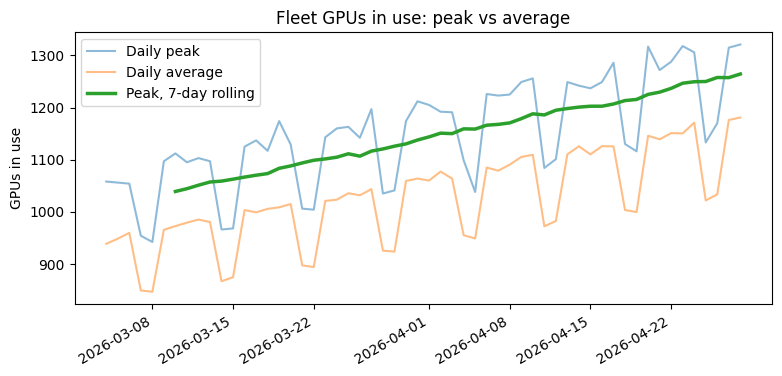

In [41]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(daily["day"], daily["peak_gpus"], alpha=0.5, label="Daily peak")
ax.plot(daily["day"], daily["avg_gpus"], alpha=0.5, label="Daily average")
ax.plot(daily["day"], daily["peak_7d_avg"], linewidth=2.5, label="Peak, 7-day rolling")
ax.set_ylabel("GPUs in use"); ax.set_title("Fleet GPUs in use: peak vs average")
ax.legend(); fig.autofmt_xdate(); plt.show()

Notice the sawtooth in the raw lines (weekends) and how the rolling line removes it so the trend shows.

**Four questions.** Imagine Claude Code wrote the block below. Answer before you run it:
1. What is the input?
2. What transformation happens?
3. What is the output?
4. How would I know if the result is wrong?

In [44]:
busiest = (
    telemetry.groupby(["gpu_type", "hour"], as_index=False)["gpus_in_use"].mean()
             .sort_values("gpus_in_use", ascending=False)
             .groupby("gpu_type")
             #.head(1)
)
busiest

✏️ **Your answers** (double-click to edit):

1. Input:gpu_type, hour, mean od gpus_in_use
2. Transformation: descending order of gpus_in_use
3. Output:
4. How I'd spot a wrong result:

---
## Wrap-up

**Add to `glossary.md` today, in your own words:**
- **Peak vs average:** size capacity to the peak (or P95); the average hides the afternoon crunch
- **GPU-hours:** GPUs × hours used; the basic unit of compute demand
- **Coincident vs non-coincident peak:** whether demand types peak at the same time; decides whether you plan to the fleet peak or the sum of peaks

**Done today when you can:**
- [ ] Explain, without notes, why the first and last weeks look low in Part 4
- [ ] Write the pandas version of `AVG(x) OVER (ORDER BY day ROWS 6 PRECEDING)`
- [ ] Say in one sentence why `sum_of_peaks` ≥ `fleet_peak`

**Tomorrow (Day 3):** Kaggle Learn *Pandas* lessons 4–6 (grouping, data types and missing values, renaming and combining), plus a notebook on merges, cleaning messy data and simple sanity checks on a trace.

---
---
## Solutions (try first!)

In [ ]:
# Exercise 1
by_weekday = telemetry.groupby("weekday")["gpus_in_use"].mean().sort_values()
by_weekday    # Saturday and Sunday are lowest: the 0.88 weekend factor in the setup

In [ ]:
# Exercise 2
daily_p95 = fleet.groupby("day", as_index=False).agg(
    avg_gpus=("gpus_in_use", "mean"),
    peak_gpus=("gpus_in_use", "max"),
    p95_gpus=("gpus_in_use", lambda s: s.quantile(0.95)),
)
daily_p95.head()

In [ ]:
# Exercise 3
weekly_full = weekly[weekly["hours"] == 168]
print(len(weekly_full), "full weeks")
weekly_full

In [ ]:
# Exercise 4
print(f"Average week-over-week growth in the fleet peak: {daily['peak_wow'].mean():.1%}")
# The setup grew H100 0.3%/day and B200 0.8%/day, so roughly 2–3% a week for the fleet. Noise moves it a bit.

In [ ]:
# Exercise 5
print(jobs.groupby("gpu_request")["gpu_hours"].sum().sort_values(ascending=False))
print(jobs["gpu_request"].value_counts())
# 1-GPU jobs are the most common, but the larger jobs use far more GPU-hours each.
# Lesson: count of jobs ≠ share of compute. Plan for the big jobs.